In [1]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "dataset" / "raw" / "CIFAKE"

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

Project root: c:\Users\KIIT\Desktop\HybridDeepTrace
Dataset path: c:\Users\KIIT\Desktop\HybridDeepTrace\dataset\raw\CIFAKE
Dataset exists: True


In [3]:
def count_images(folder):
    return sum(
        1 for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )


for split in ["train", "test"]:
    for label in ["REAL", "FAKE"]:
        folder = DATASET_PATH / split / label

        print(
            f"{split.upper()} {label}: "
            f"{count_images(folder):,} images"
        )

TRAIN REAL: 50,000 images
TRAIN FAKE: 50,000 images
TEST REAL: 10,000 images
TEST FAKE: 10,000 images


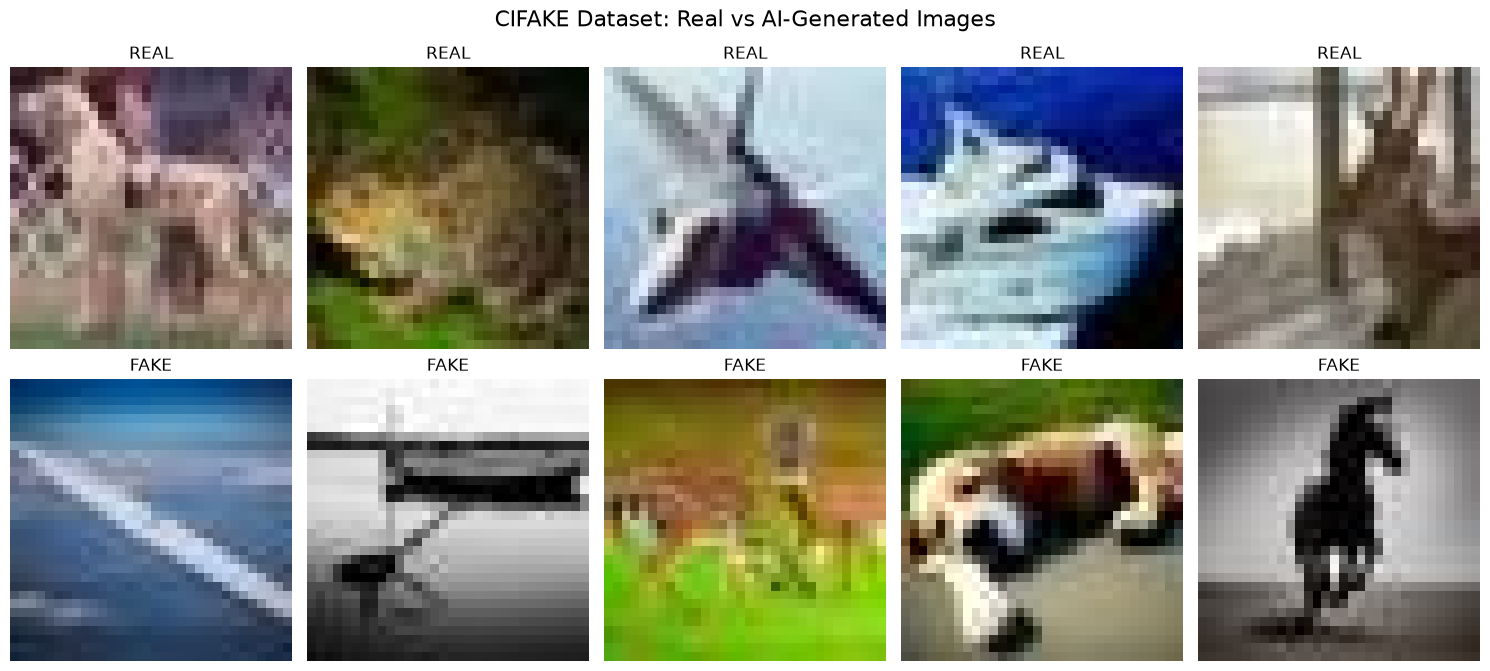

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

random.seed(42)

real_folder = TRAIN_PATH / "REAL"
fake_folder = TRAIN_PATH / "FAKE"

real_images = random.sample(
    list(real_folder.glob("*.jpg")), 5
)

fake_images = random.sample(
    list(fake_folder.glob("*.jpg")), 5
)

for i, image_path in enumerate(real_images):
    image = Image.open(image_path).convert("RGB")

    axes[0, i].imshow(image)
    axes[0, i].set_title("REAL")
    axes[0, i].axis("off")

for i, image_path in enumerate(fake_images):
    image = Image.open(image_path).convert("RGB")

    axes[1, i].imshow(image)
    axes[1, i].set_title("FAKE")
    axes[1, i].axis("off")

plt.suptitle("CIFAKE Dataset: Real vs AI-Generated Images", fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
sample_path = real_images[0]

image = Image.open(sample_path)

print("Image path:", sample_path.name)
print("Image size:", image.size)
print("Image mode:", image.mode)
print("Image format:", image.format)

Image path: 4190 (6).jpg
Image size: (32, 32)
Image mode: RGB
Image format: JPEG


In [6]:
def get_average_brightness(image_path):
    image = Image.open(image_path).convert("RGB")
    image_array = np.array(image)

    return image_array.mean()


real_brightness = [
    get_average_brightness(path)
    for path in real_images
]

fake_brightness = [
    get_average_brightness(path)
    for path in fake_images
]

print("REAL average brightness:", np.mean(real_brightness))
print("FAKE average brightness:", np.mean(fake_brightness))

REAL average brightness: 117.409375
FAKE average brightness: 113.81692708333333


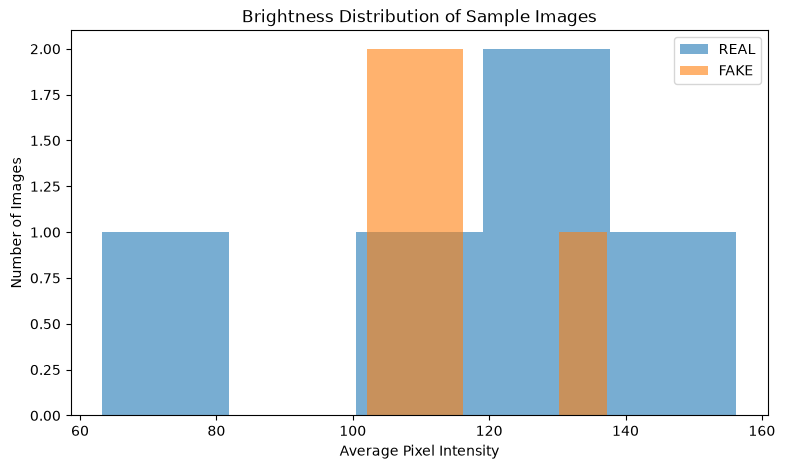

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(
    real_brightness,
    bins=5,
    alpha=0.6,
    label="REAL"
)

plt.hist(
    fake_brightness,
    bins=5,
    alpha=0.6,
    label="FAKE"
)

plt.xlabel("Average Pixel Intensity")
plt.ylabel("Number of Images")
plt.title("Brightness Distribution of Sample Images")

plt.legend()
plt.show()